# 01 · Revisión inicial del Dataset 1

**Objetivo:** conocer la tabla original de la Gobernación (cultivos permanentes del Valle, 2000-2023) antes de limpiarla: columnas, tipos, cobertura y problemas evidentes.

Fuente: *Consolidado agrícola por municipios de los cultivos permanentes del Valle del Cauca* (datos.gov.co). El archivo se lee **sin modificar** desde `data/raw/`.

In [1]:
import os, sys
from pathlib import Path
from importlib import import_module

ROOT = Path.cwd().resolve()
while not (ROOT / "config/ML_C/parametros.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src/ML_C"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import CFG, RAW, CLEAN, RES
from graficos import estilo, COLORES
estilo(); pd.set_option("display.max_columns", 30, "display.width", 160)

In [2]:
f = next(RAW.glob("*permanentes*.csv"))
raw = pd.read_csv(f, dtype=str)
print(f.name, raw.shape)
raw.head()

Consolidado_agrícola_por_municipios_de_los_cultivos_permanentes_del_Valle_del_Cauca_20260925.csv (15282, 11)


,Tipo_cultivo,Año,Id_municipio,Municipio,Id_cultivo,Cultivo,Ciclo,Hectareas_sembradas,Hectareas_cosechadas,Produccion_toneladas,Rendimiento_toneladas/hectareas
0,Frutales,"2,000","76,001",Cali,"2,040,202",Aguacate,Anual,10,8,48,6
1,Frutales,"2,000","76,001",Cali,"20,436",Cítricos,Anual,75,10,150,15
2,Frutales,"2,000","76,001",Cali,"2,043,000",Guayaba,Anual,63,43,473,11
3,Frutales,"2,000","76,001",Cali,"2,043,700",Lulo,Anual,10,9,54,6
4,Frutales,"2,000","76,001",Cali,"2,044,700",Mora,Anual,10,8,48,6


Todas las columnas llegan como texto. Los números traen **coma como separador de miles** (`"2,000"` es el año 2000 y `"76,001"` el código DANE de Cali), así que hay que limpiarlos antes de convertir.

In [3]:
num = lambda s: pd.to_numeric(s.str.replace(",", "", regex=False), errors="coerce")
x = raw.assign(anio=num(raw["Año"]), cod=num(raw["Id_municipio"]), t=num(raw["Produccion_toneladas"]))
resumen = pd.Series({
    "filas": len(x),
    "años": f"{int(x.anio.min())}-{int(x.anio.max())}",
    "municipios": x.cod.nunique(),
    "cultivos (texto original)": x.Cultivo.nunique(),
    "familias (texto original)": x.Tipo_cultivo.nunique(),
    "filas duplicadas exactas": int(raw.duplicated().sum()),
    "producción = 0": int((x.t == 0).sum()),
    "nulos en producción": int(x.t.isna().sum()),
})
resumen.to_frame("valor")

,valor
filas,15282
años,2000-2023
municipios,42
cultivos (texto original),61
familias (texto original),8
filas duplicadas exactas,18
producción = 0,295
nulos en producción,0


Las familias muestran la doble escritura de *raíces y tubérculos* que se corrige en la limpieza:

In [4]:
raw["Tipo_cultivo"].value_counts().to_frame("filas")

,filas
Tipo_cultivo,
Frutales,10130
Cultivos Tropicales Tradicionales,3087
Raíces y Tubérculos,1202
Hortalizas,596
Cultivos para Condimentos y Bebidas Medicinales y Aromáticas,119
Flores,80
Oleaginosas,65
Raíces y tubérculos,3


Cultivos que cambian de desagregación en el tiempo (aparecen tarde y parten una serie más larga):

In [5]:
ini = x.groupby("Cultivo")["anio"].agg(["min", "max"]).astype(int)
ini[ini["min"] > 2000].sort_values("min")

,min,max
Cultivo,,
Anturios,2001,2001
Aromáticas,2004,2022
Arazá,2014,2023
Cúrcuma,2014,2017
Flores y follajes,2014,2019
Durazno,2014,2023
Gulupa,2014,2023
Higuerilla,2014,2016
Sábila,2014,2023


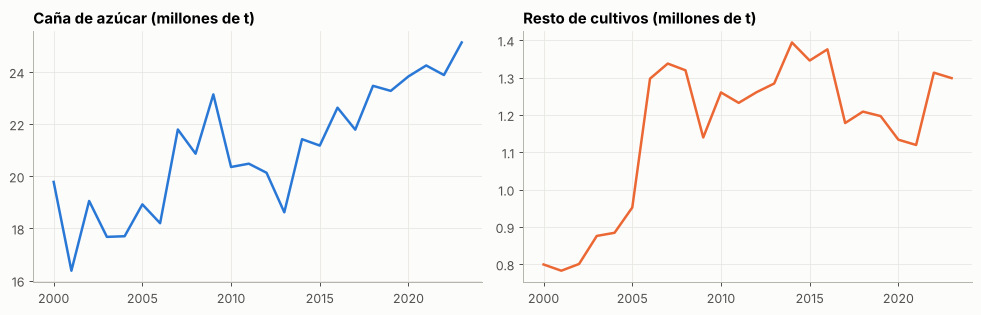

In [6]:
t = x.groupby(["anio", x.Cultivo.eq("Caña de azúcar").map({True: "Caña de azúcar", False: "Resto de cultivos"})])["t"].sum().unstack() / 1e6
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
t["Caña de azúcar"].plot(ax=axs[0], color=COLORES[0], title="Caña de azúcar (millones de t)")
t["Resto de cultivos"].plot(ax=axs[1], color=COLORES[1], title="Resto de cultivos (millones de t)")
for a in axs: a.set_xlabel("")
plt.tight_layout(); plt.show()

**Lectura.** La caña de azúcar es cerca del 96 % de las toneladas: cualquier métrica agregada en toneladas queda dominada por ella. Por eso las métricas se reportan también por producto y se calcula el valor con precios SIPSA (notebook 04).

El archivo de **transitorios** también está en `data/raw/`, pero queda como extensión del proyecto (ver `tareas_project.csv`).

In [7]:
tr = pd.read_csv(next(RAW.glob("*transitorios*.csv")), dtype=str)
print("transitorios:", tr.shape, "| cultivos:", tr.Cultivo.nunique())

transitorios: (17267, 10) | cultivos: 55
